# 07 · Baselines and linear probe (GreenPath)

**What this step does**: read the aerial-tile features extracted and cached by 06, and train a series of models from simple to complex on the dataset frozen in 05, to answer the central question of the project: **"Can we predict the ride experience from the aerial tile alone, and does the aerial tile provide information beyond OSM map data?"**

| ID | Input | Method | What it answers |
|---|---|---|---|
| **B0** | none | Predict the training-set mean | The lowest reference line; any model should beat it |
| **B1** | OSM + WorldCover (about 30 columns) | LightGBM, one model per dimension | **Strong baseline**: how far map data alone can go |
| **M1** | aerial tile | Frozen pretrained encoder features → standardize → Ridge regression | How much information the pretrained features contain by themselves (linear probe) |
| **M3** | aerial tile + OSM | Image features compressed with PCA and concatenated with the OSM features → LightGBM | **The key one**: can the aerial tile add information OSM does not have? |

M1 tries three pretrained encoders, **ResNet-50** (ImageNet), **DINOv2 ViT-S/14**, and **CLIP ViT-B/16**, and the best one by cross-validation goes on to M3.

| | Path (relative to the data root) |
|---|---|
| Input: frozen dataset | `datasets/{version}/dataset.parquet`, `schema.json` |
| Input: aerial-tile features (from 06) | `embeddings/{version}/{encoder}.parquet` |
| Output: metrics, predictions, configuration | `results/{run_id}/…`, accumulated in `results/metrics.parquet` |
| Output: **experiment log** | `docs/EXPERIMENTS.md` (in the project directory; one section is appended per run) |

**How we evaluate (to avoid fooling ourselves)**
- **Model and hyperparameter selection use cross-validation only**: **5 spatially grouped folds by block** over train+val, never touching the test set. The encoder, the regularization strength α, the LightGBM parameters, and the PCA dimension are all chosen automatically by the CV score; there is no step where a person looks at the test set.
- **The test set is evaluated only once, at the end**: the selected models are retrained on all of train+val and scored once on the test set.
- **Per-dimension Spearman** (whether the ranking agrees; route planning only cares about relative order) plus MAE; confidence intervals use a **block bootstrap**, because cells in the same block are not independent.
- The difference between two models (e.g. M3 − B1) also gets a confidence interval: only an interval that excludes 0 counts as really better.

**Why the features are extracted in a separate notebook (06)**: PyTorch and LightGBM cannot live in the same process on a Mac (each ships its own OpenMP library, and loading both crashes). So feature extraction (torch only) and baseline training (LightGBM / sklearn only) are separate, which also matches the two containers we will have later.

**Note**: the labels are generated by Gemini and are **not yet validated by humans** (E1). Every "accuracy" here is relative to Gemini's scores, not to the true ride experience.

## 1. Install dependencies (runs only on Colab)

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:      # Install automatically only on Colab; locally, install the dependencies beforehand
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "lightgbm", "scikit-learn", "scipy", "tabulate", "pandas", "pyarrow", "gcsfs", "matplotlib", "tqdm", "fsspec"], check=True)

## 2. Configuration
- `DATASET_VERSION`: which frozen dataset version to use.
- `BACKBONES`, `TTA`: whose features to use, and whether test-time augmentation was used. **They must match the settings used when extracting in 06** (they decide which cache file is read).
- `RIDGE_ALPHAS`: candidate Ridge regularization strengths; `PCA_DIMS`: candidate numbers of dimensions the image features are compressed to in M3; `LGB_GRID`: candidate LightGBM parameters.
- `N_BOOT`: number of bootstrap resamples (larger gives more accurate intervals but is slower).
- `RUN_NAME`: a name for this experiment, written into the experiment log.

In [2]:
DATASET_VERSION = "v1"
RUN_NAME = "baselines-first-run"

BACKBONES = ["resnet50", "dinov2_s", "clip_b16"]
TTA = True

RIDGE_ALPHAS = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]
PCA_DIMS = [16, 32, 64]
LGB_GRID = [dict(n_estimators=n, num_leaves=l) for n in (150, 400) for l in (7, 15)]
LGB_BASE = dict(learning_rate=0.05, min_child_samples=20, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, reg_lambda=1.0)
N_BOOT = 500
SEED = 42

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. Connect to storage and read the dataset

In [3]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # On Colab, log in here; locally, first run gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # later, containers can set the data directory through an environment variable
    fs = fsspec.filesystem("file")

def path(*parts):
    # build the full path under the data root, e.g. path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS has no real directories, so there is nothing to create
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # use a system CJK font so any CJK text in charts renders correctly
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("Data root:", ROOT)

Data root: ./data


In [4]:
import numpy as np, time, os

# ⚠ Do not import torch in this notebook: it and LightGBM each ship their own OpenMP library, and loading both in one process crashes (macOS).
# The image features are extracted and cached separately by 06.
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DIMS = ["traffic_intensity", "quietness", "shade", "naturalness",
        "scenic_appeal", "historic_character", "liveliness", "visual_openness"]
ds_dir = f"datasets/{DATASET_VERSION}"
ds = read_parquet(path(ds_dir, "dataset.parquet")).sort_values("cell_id").reset_index(drop=True)
with fs.open(path(ds_dir, "schema.json"), "r") as f:
    schema = json.load(f)

tab = ds[schema["tabular"]].astype("float32")
for c in schema["categorical"]:                                      # categorical features (e.g. wc_dominant) → one-hot encoding
    tab = pd.concat([tab, pd.get_dummies(ds[c], prefix=c).astype("float32")], axis=1)
TAB = tab.values
Y = ds[DIMS].values.astype("float64")
pool = np.where(ds.split.isin(["train", "val"]))[0]                  # used for model selection
test = np.where(ds.split == "test")[0]                               # looked at only once, at the end
fold = ds.fold.astype("float").values
block = ds.block_id.values
run_id = f"{RUN_NAME}-{datetime.datetime.utcnow().strftime('%Y%m%dT%H%M')}"
print(f"Dataset {DATASET_VERSION}: {len(ds)} cells | {len(pool)} used for model selection (5 folds) | {len(test)} test")
print(f"{TAB.shape[1]} tabular feature columns | {len(DIMS)} label dimensions | run_id = {run_id}")

Dataset v1: 1012 cells | 824 used for model selection (5 folds) | 188 test
32 tabular feature columns | 8 label dimensions | run_id = baselines-first-run-20261013T0242


## 4. Read the aerial-tile features (cached by 06)
**How the "foundation model" is used here**: the pretrained encoder has already learned to "see" on a huge number of images; 06 turned every 224×224 aerial tile into a feature vector (a few hundred numbers) and cached it. We read it directly here, **the encoder takes no part in training** ("frozen"), and only the regression head that follows is learning.

In [5]:
EMB, EMB_META = {}, {}
for name in BACKBONES:
    rel = f"embeddings/{DATASET_VERSION}/{name}{'_tta' if TTA else ''}.parquet"
    if not fs.exists(path(rel)):
        raise FileNotFoundError(f"{rel} not found: run the 06 embeddings notebook first to extract the features (BACKBONES and TTA must match here)")
    e = read_parquet(path(rel)).set_index("cell_id").reindex(ds.cell_id)
    assert not e.isna().any().any(), f"The features of {name} are missing some cells; please rerun 06"
    EMB[name] = e.values.astype("float32")
    print(f"{name}: {EMB[name].shape}")
meta_path = path("embeddings", DATASET_VERSION, "meta.json")
if fs.exists(meta_path):
    with fs.open(meta_path, "r") as f:
        EMB_META = json.load(f)

resnet50: (1012, 2048)
dinov2_s: (1012, 384)
clip_b16: (1012, 512)


## 5. Evaluation tools
- `spearman_cols`: per-dimension Spearman. When the predictions are completely constant (as for B0) the correlation is undefined and is recorded as 0.
- **Block bootstrap**: each time, blocks are drawn with replacement (all cells of a block are drawn together) instead of single cells, because cells in the same block resemble each other and are not independent; only then are the confidence intervals not too narrow.
- Two models are compared on **the same resamples**, so that the interval of their difference is meaningful.

In [6]:
def spearman_cols(yt, yp):
    out = []
    for j in range(yt.shape[1]):
        ok = ~np.isnan(yt[:, j]) & ~np.isnan(yp[:, j])
        if ok.sum() < 5 or np.ptp(yp[ok, j]) == 0 or np.ptp(yt[ok, j]) == 0:
            out.append(0.0)
        else:
            out.append(spearmanr(yt[ok, j], yp[ok, j]).correlation)
    return np.array(out)

def mae_cols(yt, yp):
    return np.nanmean(np.abs(yt - yp), axis=0)

def block_resamples(groups, n, seed):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups); idx = {g: np.where(groups == g)[0] for g in ug}
    return [np.concatenate([idx[g] for g in rng.choice(ug, len(ug), replace=True)]) for _ in range(n)]

def boot(yt, yp, rs):
    return np.array([spearman_cols(yt[r], yp[r]) for r in rs])          # n_boot × number of dimensions

def ci(b):
    return np.nanpercentile(b, [2.5, 97.5], axis=0)

rs_cv = block_resamples(block[pool], N_BOOT, SEED)
rs_te = block_resamples(block[test], N_BOOT, SEED + 1)

## 6. Models
Four "prediction functions" with the same signature: `predict(training rows, prediction rows, parameters) → predictions`. Both cross-validation and the final test use them, so the same code is used in both places.
- Each dimension is trained separately, using only the rows that have a label for that dimension (a missing label is never treated as 0);
- Predictions are clipped to 0–1, matching the label range;
- The standardization of Ridge and PCA is fitted on the training rows only and never peeks at the validation rows.

In [7]:
def p_b0(tr, te):
    return np.tile(np.nanmean(Y[tr], axis=0), (len(te), 1))

def p_b1(tr, te, P):
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = tr[~np.isnan(Y[tr, j])]
        m = lgb.LGBMRegressor(**LGB_BASE, **P, random_state=SEED, verbose=-1, n_jobs=4).fit(TAB[ok], Y[ok, j])
        out[:, j] = m.predict(TAB[te])
    return np.clip(out, 0, 1)

def p_m1(tr, te, name, alpha):
    E = EMB[name]; sc = StandardScaler().fit(E[tr]); Xtr, Xte = sc.transform(E[tr]), sc.transform(E[te])
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = ~np.isnan(Y[tr, j])
        out[:, j] = Ridge(alpha=alpha).fit(Xtr[ok], Y[tr][ok, j]).predict(Xte)
    return np.clip(out, 0, 1)

def p_m3(tr, te, name, P, k):
    E = EMB[name]; sc = StandardScaler().fit(E[tr]); pca = PCA(k, random_state=SEED).fit(sc.transform(E[tr]))
    Xtr = np.hstack([pca.transform(sc.transform(E[tr])), TAB[tr]]); Xte = np.hstack([pca.transform(sc.transform(E[te])), TAB[te]])
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = ~np.isnan(Y[tr, j])
        m = lgb.LGBMRegressor(**LGB_BASE, **P, random_state=SEED, verbose=-1, n_jobs=4).fit(Xtr[ok], Y[tr][ok, j])
        out[:, j] = m.predict(Xte)
    return np.clip(out, 0, 1)

def run_cv(fn, **kw):
    # 5 folds split by block: each fold takes a turn as validation and the rest are for training; returns the "out-of-fold predictions" of all train+val cells
    oof = np.zeros((len(pool), len(DIMS))); pf = fold[pool]
    for k in np.unique(pf):
        te_pos, tr_pos = np.where(pf == k)[0], np.where(pf != k)[0]
        oof[te_pos] = fn(pool[tr_pos], pool[te_pos], **kw)
    return oof

cv_score = lambda oof: spearman_cols(Y[pool], oof).mean()          # used for model selection: mean Spearman over the 8 dimensions
PRED_CV, CHOSEN = {}, {}

## 7. B0 and B1: baselines that do not look at images
**B1 is the key reference**: if the aerial-tile model cannot even beat "OSM table only", then the aerial tile adds no extra value. The LightGBM parameters are chosen from `LGB_GRID` by cross-validation.

In [8]:
t0 = time.time()
PRED_CV["B0"] = run_cv(p_b0)
rows = []
for P in LGB_GRID:
    oof = run_cv(p_b1, P=P); rows.append((P, cv_score(oof), oof))
rows.sort(key=lambda r: -r[1])
CHOSEN["B1"] = rows[0][0]; PRED_CV["B1"] = rows[0][2]
print(f"B1 candidates (CV mean Spearman):")
for P, s, _ in rows:
    print(f"  {P}  →  {s:.3f}" + ("   ← selected" if P is CHOSEN["B1"] else ""))
print(f"B0 is a constant prediction, so its Spearman is 0 by definition (only MAE is meaningful) | took {time.time() - t0:.0f} s")

B1 candidates (CV mean Spearman):
  {'n_estimators': 150, 'num_leaves': 7}  →  0.573   ← selected
  {'n_estimators': 150, 'num_leaves': 15}  →  0.568
  {'n_estimators': 400, 'num_leaves': 7}  →  0.561
  {'n_estimators': 400, 'num_leaves': 15}  →  0.557
B0 is a constant prediction, so its Spearman is 0 by definition (only MAE is meaningful) | took 27 s


## 8. M1: frozen encoder + linear regression head
For each encoder, the best regularization strength α is chosen from `RIDGE_ALPHAS` by cross-validation; then, among the three encoders, the one with the highest CV score is selected for use in M3 below.

In [9]:
t0 = time.time()
m1 = {}
for name in BACKBONES:
    best = None
    for a in RIDGE_ALPHAS:
        oof = run_cv(p_m1, name=name, alpha=a); s = cv_score(oof)
        if best is None or s > best[1]:
            best = (a, s, oof)
    m1[name] = best
    CHOSEN[f"M1_{name}"] = {"alpha": best[0]}; PRED_CV[f"M1_{name}"] = best[2]
res = pd.DataFrame({n: {"best α": v[0], "CV mean Spearman": round(v[1], 3)} for n, v in m1.items()}).T
BEST_BB = max(m1, key=lambda n: m1[n][1])
CHOSEN["best_backbone"] = BEST_BB
print(res.to_string(), f"\n→ selected encoder: {BEST_BB} | took {time.time() - t0:.0f} s")

          best α  CV mean Spearman
resnet50  3000.0             0.539
dinov2_s  1000.0             0.542
clip_b16  1000.0             0.548 
→ selected encoder: clip_b16 | took 3 s


## 9. M3: image features + OSM features
With the encoder selected above: standardize the image features, compress them with PCA to `k` dimensions, concatenate them with the OSM features into one wide table, and hand it to LightGBM (using the parameter set selected for B1). `k` is also chosen by cross-validation.

In [10]:
t0 = time.time()
best = None
for k in PCA_DIMS:
    oof = run_cv(p_m3, name=BEST_BB, P=CHOSEN["B1"], k=k); s = cv_score(oof)
    print(f"  PCA {k:>3} dims  →  CV mean Spearman {s:.3f}")
    if best is None or s > best[1]:
        best = (k, s, oof)
CHOSEN["M3"] = {"backbone": BEST_BB, "pca": best[0], "lgb": CHOSEN["B1"]}; PRED_CV["M3"] = best[2]
print(f"→ selected PCA {best[0]} dims | took {time.time() - t0:.0f} s")

  PCA  16 dims  →  CV mean Spearman 0.588
  PCA  32 dims  →  CV mean Spearman 0.591
  PCA  64 dims  →  CV mean Spearman 0.582
→ selected PCA 32 dims | took 9 s


## 10. Final evaluation: the test set, looked at only this once
Retrain each of the models selected above on **all** of train+val and predict the test set once. Afterwards nothing is changed in response to the test result; if you want to change something, bump the dataset or the experiment version and start again.

In [11]:
tr_all = pool
PRED_TE = {"B0": p_b0(tr_all, test),
           "B1": p_b1(tr_all, test, CHOSEN["B1"])}
for name in BACKBONES:
    PRED_TE[f"M1_{name}"] = p_m1(tr_all, test, name, CHOSEN[f"M1_{name}"]["alpha"])
PRED_TE["M3"] = p_m3(tr_all, test, BEST_BB, CHOSEN["M3"]["lgb"], CHOSEN["M3"]["pca"])
PRED_TE["M1"] = PRED_TE[f"M1_{BEST_BB}"]; PRED_CV["M1"] = PRED_CV[f"M1_{BEST_BB}"]       # M1 = the one with the best encoder
print("Predicted on the test set:", list(PRED_TE))

Predicted on the test set: ['B0', 'B1', 'M1_resnet50', 'M1_dinov2_s', 'M1_clip_b16', 'M3', 'M1']


## 11. Results
Per-dimension Spearman and 95% confidence intervals (block bootstrap), plus the differences of M3 and M1 relative to B1. **A difference counts as really better only if its interval excludes 0.**

In [12]:
MODELS = ["B0", "B1", "M1", "M3"]
rows, B = [], {}
for split, PRED, idx, rs in [("cv", PRED_CV, pool, rs_cv), ("test", PRED_TE, test, rs_te)]:
    for m in MODELS:
        yt, yp = Y[idx], PRED[m]
        b = boot(yt, yp, rs); lo, hi = ci(b); pt = spearman_cols(yt, yp); mae = mae_cols(yt, yp)
        if m == "B0":                      # constant prediction: Spearman is 0 by definition (in cross-validation each fold has a different constant, and stitching them together creates a spurious correlation)
            b = np.zeros_like(b); lo = hi = pt = np.zeros(len(DIMS))
        B[(split, m)] = b
        for j, d in enumerate(DIMS):
            rows.append(dict(run_id=run_id, split=split, model=m, dim=d, spearman=pt[j], ci_lo=lo[j], ci_hi=hi[j],
                             mae=mae[j], n=int((~np.isnan(yt[:, j])).sum())))
R = pd.DataFrame(rows)

def table(split):
    t = R[R.split == split].pivot(index="dim", columns="model", values="spearman").reindex(DIMS)[MODELS]
    lo = R[R.split == split].pivot(index="dim", columns="model", values="ci_lo").reindex(DIMS)[MODELS]
    hi = R[R.split == split].pivot(index="dim", columns="model", values="ci_hi").reindex(DIMS)[MODELS]
    out = t.round(2).astype(str) + " [" + lo.round(2).astype(str) + ", " + hi.round(2).astype(str) + "]"
    out.loc["Mean"] = [f"{t[m].mean():.2f}" for m in MODELS]
    return out

DIFF = []
for split in ("cv", "test"):
    for m, ref in [("M3", "B1"), ("M1", "B1"), ("M3", "M1")]:
        d = B[(split, m)] - B[(split, ref)]; lo, hi = ci(d)
        pt = R[(R.split == split) & (R.model == m)].spearman.values - R[(R.split == split) & (R.model == ref)].spearman.values
        for j, dim in enumerate(DIMS):
            DIFF.append(dict(split=split, comparison=f"{m} − {ref}", dim=dim, diff=pt[j], ci_lo=lo[j], ci_hi=hi[j],
                             better=bool(lo[j] > 0), worse=bool(hi[j] < 0)))
DIFF = pd.DataFrame(DIFF)

print("Cross-validation (train+val, out-of-fold predictions), per-dimension Spearman [95% CI]"); display(table("cv"))
print("\nTest set (final), per-dimension Spearman [95% CI]"); display(table("test"))
s = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M3 − B1")]
print(f"\nM3 − B1 on the test set: {int(s.better.sum())}/8 dimensions significantly better, {int(s.worse.sum())}/8 significantly worse; mean difference {s['diff'].mean():+.3f}")
s = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M1 − B1")]
print(f"M1 − B1 on the test set: {int(s.better.sum())}/8 dimensions significantly better, {int(s.worse.sum())}/8 significantly worse; mean difference {s['diff'].mean():+.3f}")

Cross-validation (train+val, out-of-fold predictions), per-dimension Spearman [95% CI]


model,B0,B1,M1,M3
dim,,,,
traffic_intensity,"0.0 [0.0, 0.0]","0.62 [0.52, 0.71]","0.58 [0.48, 0.66]","0.64 [0.56, 0.71]"
quietness,"0.0 [0.0, 0.0]","0.66 [0.56, 0.73]","0.63 [0.53, 0.7]","0.66 [0.57, 0.73]"
shade,"0.0 [0.0, 0.0]","0.45 [0.34, 0.54]","0.32 [0.2, 0.43]","0.4 [0.29, 0.5]"
naturalness,"0.0 [0.0, 0.0]","0.71 [0.63, 0.77]","0.69 [0.62, 0.75]","0.71 [0.64, 0.77]"
scenic_appeal,"0.0 [0.0, 0.0]","0.67 [0.57, 0.74]","0.68 [0.6, 0.75]","0.69 [0.6, 0.76]"
historic_character,"0.0 [0.0, 0.0]","0.57 [0.46, 0.66]","0.66 [0.57, 0.73]","0.65 [0.56, 0.72]"
liveliness,"0.0 [0.0, 0.0]","0.66 [0.58, 0.71]","0.55 [0.45, 0.63]","0.66 [0.58, 0.73]"
visual_openness,"0.0 [0.0, 0.0]","0.26 [0.11, 0.39]","0.27 [0.15, 0.38]","0.31 [0.19, 0.43]"
Mean,0.00,0.57,0.55,0.59



Test set (final), per-dimension Spearman [95% CI]


model,B0,B1,M1,M3
dim,,,,
traffic_intensity,"0.0 [0.0, 0.0]","0.62 [0.47, 0.76]","0.35 [0.1, 0.6]","0.55 [0.39, 0.73]"
quietness,"0.0 [0.0, 0.0]","0.67 [0.48, 0.79]","0.44 [0.15, 0.62]","0.66 [0.49, 0.79]"
shade,"0.0 [0.0, 0.0]","0.46 [0.07, 0.69]","0.28 [-0.04, 0.53]","0.4 [-0.02, 0.65]"
naturalness,"0.0 [0.0, 0.0]","0.58 [0.35, 0.7]","0.56 [0.31, 0.71]","0.6 [0.35, 0.72]"
scenic_appeal,"0.0 [0.0, 0.0]","0.53 [0.36, 0.68]","0.51 [0.3, 0.65]","0.57 [0.41, 0.7]"
historic_character,"0.0 [0.0, 0.0]","0.51 [0.27, 0.67]","0.56 [0.34, 0.68]","0.57 [0.37, 0.69]"
liveliness,"0.0 [0.0, 0.0]","0.68 [0.54, 0.77]","0.57 [0.36, 0.67]","0.67 [0.54, 0.74]"
visual_openness,"0.0 [0.0, 0.0]","0.17 [-0.21, 0.4]","0.26 [0.01, 0.38]","0.23 [-0.07, 0.4]"
Mean,0.00,0.53,0.44,0.53



M3 − B1 on the test set: 0/8 dimensions significantly better, 0/8 significantly worse; mean difference +0.002
M1 − B1 on the test set: 0/8 dimensions significantly better, 4/8 significantly worse; mean difference -0.086


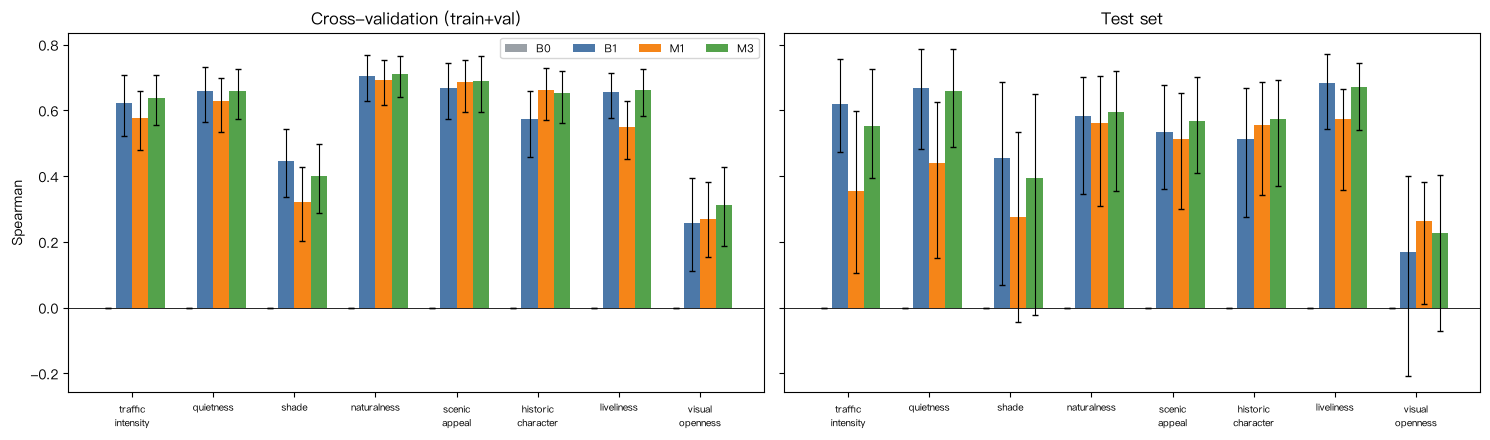

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
colors = {"B0": "#9aa0a6", "B1": "#4c78a8", "M1": "#f58518", "M3": "#54a24b"}
for ax, split, title in [(axes[0], "cv", "Cross-validation (train+val)"), (axes[1], "test", "Test set")]:
    w = 0.2
    for i, m in enumerate(MODELS):
        r = R[(R.split == split) & (R.model == m)].set_index("dim").reindex(DIMS)
        x = np.arange(len(DIMS)) + (i - 1.5) * w
        ax.bar(x, r.spearman, w, label=m, color=colors[m],
               yerr=[(r.spearman - r.ci_lo).clip(lower=0), (r.ci_hi - r.spearman).clip(lower=0)], capsize=2, error_kw=dict(lw=.8))
    ax.set_xticks(range(len(DIMS))); ax.set_xticklabels([d.replace("_", "\n") for d in DIMS], fontsize=7)
    ax.axhline(0, c="k", lw=.6); ax.set_title(title); ax.set_ylabel("Spearman" if split == "cv" else "")
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 12. Save the results, predictions, and the experiment log

In [14]:
out_dir = f"results/{run_id}"
makedirs(path("results")); makedirs(path(out_dir))
write_parquet(R, path(out_dir, "metrics.parquet"))
write_parquet(DIFF, path(out_dir, "comparisons.parquet"))
allp = path("results", "metrics.parquet")
write_parquet(pd.concat([read_parquet(allp), R], ignore_index=True) if fs.exists(allp) else R, allp)

cv_df = pd.DataFrame({"cell_id": ds.cell_id.values[pool], "split": "cv", **{f"{m}__{d}": PRED_CV[m][:, j] for m in MODELS for j, d in enumerate(DIMS)}})
te_df = pd.DataFrame({"cell_id": ds.cell_id.values[test], "split": "test", **{f"{m}__{d}": PRED_TE[m][:, j] for m in MODELS for j, d in enumerate(DIMS)}})
write_parquet(pd.concat([cv_df, te_df], ignore_index=True), path(out_dir, "predictions.parquet"))

config = {"run_id": run_id, "dataset_version": DATASET_VERSION, "backbones": BACKBONES, "tta": TTA, "embedding_meta": EMB_META,
          "chosen": {k: v for k, v in CHOSEN.items()}, "ridge_alphas": RIDGE_ALPHAS, "pca_dims": PCA_DIMS,
          "lgb_base": LGB_BASE, "lgb_grid": LGB_GRID, "n_boot": N_BOOT, "seed": SEED,
          "n_pool": int(len(pool)), "n_test": int(len(test)),
          "versions": {"lightgbm": lgb.__version__},
          "label_validation": "pending (E1)"}
with fs.open(path(out_dir, "config.json"), "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False, default=str)

# ---- experiment log (appended to docs/EXPERIMENTS.md in the project directory) ----
te = R[R.split == "test"]
mean_te = {m: te[te.model == m].spearman.mean() for m in MODELS}
d_m3 = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M3 − B1")]
d_m1 = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M1 − B1")]
weak = te[te.model == "M3"].sort_values("spearman").query("spearman < 0.3").dim.tolist()
good = te[te.model == "M3"].sort_values("spearman", ascending=False).query("spearman >= 0.5").dim.tolist()
concl = [f"- Best encoder (CV): **{BEST_BB}**; PCA dimension for M3: {CHOSEN['M3']['pca']}; LightGBM parameters: {CHOSEN['B1']}.",
         f"- Mean test Spearman: B0 {mean_te['B0']:.2f} · B1 {mean_te['B1']:.2f} · M1 {mean_te['M1']:.2f} · M3 {mean_te['M3']:.2f}.",
         f"- M3 vs B1: {int(d_m3.better.sum())}/8 dimensions significantly better (CI excludes 0), {int(d_m3.worse.sum())}/8 significantly worse, mean difference {d_m3['diff'].mean():+.3f}.",
         f"- M1 (aerial tile only) vs B1: {int(d_m1.better.sum())}/8 significantly better, {int(d_m1.worse.sum())}/8 significantly worse, mean difference {d_m1['diff'].mean():+.3f}.",
         f"- More predictable dimensions (M3 test Spearman ≥ 0.5): {', '.join(good) or 'none'}; weaker dimensions (< 0.3): {', '.join(weak) or 'none'}."]
nxt = []
better_dims = d_m3[d_m3.better].dim.tolist()
if len(better_dims) >= 3 and d_m3["diff"].mean() > 0:
    nxt.append(f"The fusion model is significantly better than the OSM baseline on {len(better_dims)} dimensions ({', '.join(better_dims)}): next try end-to-end fine-tuning (M2) and compare with a remote-sensing-specific encoder (SatlasPretrain).")
elif better_dims:
    nxt.append(f"The fusion model is significantly better than the OSM baseline only on a few dimensions ({', '.join(better_dims)}), with an overall mean difference of {d_m3['diff'].mean():+.3f}: the added value of the aerial tile is limited. First run E1 to confirm the labels are reliable, then try a remote-sensing-specific encoder and fine-tuning (M2).")
else:
    nxt.append("The aerial-tile features do not significantly beat the OSM baseline: first check the label quality (E1) and whether the encoder is suitable, then try a remote-sensing-specific encoder (SatlasPretrain) and fine-tuning (M2).")
if weak:
    nxt.append(f"Weak dimensions ({', '.join(weak)}): go back to E1 to see whether the labels are unreliable or the top-down view simply cannot predict them; for unreliable dimensions, consider dropping them or rewriting the scoring rules.")
nxt += ["Run the E1 human annotation and draw conclusions only for the dimensions that pass.", "Scale up the data: an ablation that relaxes the winter filter; add a second city for a true cross-city test."]

section = f"""
## {run_id}

- **Date**: {now_iso()} · **Dataset**: {DATASET_VERSION} ({len(pool)} train / val cells, {len(test)} test cells) · TTA: {TTA}
- **Goal**: answer "Can we predict the ride experience from the aerial tile alone, and does the aerial tile provide information beyond OSM?"
- **Labels**: generated by Gemini, **not yet validated by humans (E1)**. Every "accuracy" below is relative to Gemini's scores.

### Test-set results (Spearman [95% CI], block bootstrap)

{table('test').to_markdown()}

### Conclusions
{chr(10).join(concl)}

### Plan for the next iteration
{chr(10).join('- ' + x for x in nxt)}

### Notes (fill in by hand)
- 
"""
if STORAGE == "local":
    os.makedirs("docs", exist_ok=True)
    with open("docs/EXPERIMENTS.md", "a", encoding="utf-8") as f:
        if os.path.getsize("docs/EXPERIMENTS.md") == 0 if os.path.exists("docs/EXPERIMENTS.md") else True:
            f.write("# GreenPath experiment log\n\nEach run of `07_baselines.ipynb` appends one section.\n")
        f.write(section)
    print("Appended to docs/EXPERIMENTS.md")
print("\n".join(concl))

Appended to docs/EXPERIMENTS.md
- Best encoder (CV): **clip_b16**; PCA dimension for M3: 32; LightGBM parameters: {'n_estimators': 150, 'num_leaves': 7}.
- Mean test Spearman: B0 0.00 · B1 0.53 · M1 0.44 · M3 0.53.
- M3 vs B1: 0/8 dimensions significantly better (CI excludes 0), 0/8 significantly worse, mean difference +0.002.
- M1 (aerial tile only) vs B1: 0/8 significantly better, 4/8 significantly worse, mean difference -0.086.
- More predictable dimensions (M3 test Spearman ≥ 0.5): liveliness, quietness, naturalness, historic_character, scenic_appeal, traffic_intensity; weaker dimensions (< 0.3): visual_openness.


## 13. Run record

In [15]:
write_manifest({"step": "07_baselines", "run_id": run_id, "dataset_version": DATASET_VERSION,
                "chosen": {k: str(v) for k, v in CHOSEN.items()},
                "test_mean_spearman": {m: round(float(mean_te[m]), 4) for m in MODELS},
                "outputs": [out_dir, "results/metrics.parquet", "docs/EXPERIMENTS.md"],
                "finished_at": now_iso()}, "07_baselines_manifest.json")
print("Done:", out_dir)

Done: results/baselines-first-run-20261013T0242


## Next steps
- **E1**: validate the labels with the human annotation sheet in `processed/qa/` and decide which dimensions can be trusted.
- **M2 (fine-tuning)**: train the encoder and the regression head together (layer-wise learning rates, masked MSE, early stopping on the validation Spearman), on a Vertex AI GPU or the Mac's MPS.
- Remote-sensing-specific encoders (SatlasPretrain), and a second city (Providence) for cross-city testing.
- Containerization: move 01–07 into Docker so that one `docker compose up` command runs everything.